# 08 — Explainable Boosting Machine (EBM/GAM) per generator

**Group 119 — Henrik Remmen (541747)**  
**Kaggle team:** `[119] SINTEF Databreach`

This notebook trains one Explainable Boosting Machine per generator. EBM is a glass-box generalized additive model with optional pairwise interactions. It is included as a smoother, more interpretable and potentially more shift-robust alternative to unrestricted gradient-boosted trees.

Design choices:

- purged chronological outer validation;
- a curated numeric feature set rather than every generated feature;
- four domain-motivated interactions rather than automatic interaction mining;
- one outer bag, 30% deterministic row sampling, and reduced bin counts to satisfy the 12-hour limit;
- no random hyperparameter search.

> Saved unexecuted. You run all model cells yourself.


## 1. Setup and shared project data

Install the added dependency once with `pip install -r requirements.txt` and restart the kernel if necessary.

In [1]:
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.sintef_pipeline import (
    HORIZON,
    RANDOM_SEED,
    build_project_data,
    make_submission,
    micro_auc,
    per_unit_auc,
    rows_for_cases,
)

try:
    from interpret.glassbox import ExplainableBoostingClassifier
except ImportError as error:
    raise ImportError(
        "Run 'pip install -r requirements.txt', restart the kernel, "
        "and rerun this cell."
    ) from error

sns.set_theme(style="whitegrid", context="notebook")
N_JOBS = 4

print("Project root:", ROOT.resolve())


Project root: /Users/henrik/Documents/H26/Moderne Maksinlæring/sintef_project


In [2]:
# DATA/FEATURE CELL — no model training
data = build_project_data(ROOT)
all_features = data.X_all.columns.tolist()
baseline = data.feature_sets["baseline"]

# Runtime-controlled EBM representation: strong aggregate and local price
# features, without dozens of correlated reservoir-specific main effects.
explicit_features = [
    "price_week_zscore", "price_top_10pct", "price_bottom_10pct",
    "price_mean_6h", "price_minus_mean_6h",
    "price_mean_24h", "price_minus_mean_24h",
    "price_mean_48h", "price_minus_mean_48h",
    "price_to_abs_water_value_ratio",
    "inflow_total_week_mean", "inflow_total_week_std",
    "inflow_total_cumulative_mean",
    "min_flow_active_count", "min_volume_active_count",
]

FEATURES = list(dict.fromkeys(
    feature for feature in baseline + explicit_features
    if feature in all_features
))
TRAIN_ROW_FRACTION = 0.30

interaction_names = [
    ("price_minus_water_value_mean", "system_filling_ratio"),
    ("price_week_percentile", "system_filling_ratio"),
    ("price_minus_water_value_mean", "inflow_total_24h_mean"),
    ("price_minus_water_value_mean", "variable_constraint_active"),
]
INTERACTIONS = [
    (FEATURES.index(left), FEATURES.index(right))
    for left, right in interaction_names
    if left in FEATURES and right in FEATURES
]

print("EBM features:", len(FEATURES))
print("Training-row fraction:", TRAIN_ROW_FRACTION)
print("Explicit pair interactions:", len(INTERACTIONS))
display(pd.DataFrame(interaction_names, columns=["feature_1", "feature_2"]))


EBM features: 35
Training-row fraction: 0.3
Explicit pair interactions: 4


,feature_1,feature_2
0,price_minus_water_value_mean,system_filling_ratio
1,price_week_percentile,system_filling_ratio
2,price_minus_water_value_mean,inflow_total_24h_mean
3,price_minus_water_value_mean,variable_constraint_active


## 2. Model and chronological OOF evaluation

EBM performs internal bagging only inside each outer training period. The untouched next-year fold remains the only source of reported validation performance.

In [3]:
EBM_PARAMS = {
    "feature_names": FEATURES,
    "interactions": INTERACTIONS,
    "max_bins": 64,
    "max_interaction_bins": 16,
    "outer_bags": 1,
    "inner_bags": 0,
    "validation_size": 0.10,
    "learning_rate": 0.05,
    "max_rounds": 1200,
    "early_stopping_rounds": 50,
    "early_stopping_tolerance": 1e-5,
    "min_samples_leaf": 50,
    "max_leaves": 2,
    "greedy_ratio": 5.0,
    "n_jobs": N_JOBS,
    "random_state": RANDOM_SEED,
}

def make_ebm(seed=RANDOM_SEED):
    params = dict(EBM_PARAMS)
    params["random_state"] = seed
    return ExplainableBoostingClassifier(**params)

def sampled_row_positions(n_rows, fraction, seed):
    if fraction >= 1:
        return np.arange(n_rows)
    rng = np.random.default_rng(seed)
    sample_size = max(1, int(n_rows*fraction))
    return np.sort(rng.choice(n_rows, size=sample_size, replace=False))

def evaluate_ebm_per_generator():
    oof = np.full(data.target_cube.shape, np.nan, dtype=np.float32)
    fold_rows = []
    unit_rows = []

    for fold in data.folds:
        started = time.perf_counter()
        train_case_ids = fold["train_cases"]
        val_case_ids = fold["validation_cases"]
        train_rows_full = rows_for_cases(train_case_ids)
        selected = sampled_row_positions(
            len(train_rows_full),
            TRAIN_ROW_FRACTION,
            RANDOM_SEED + fold["year"],
        )
        train_rows = train_rows_full[selected]
        val_rows = rows_for_cases(val_case_ids)
        X_train = data.X_all.loc[train_rows, FEATURES]
        X_val = data.X_all.loc[val_rows, FEATURES]
        fold_prediction = np.empty(
            (len(val_case_ids), len(data.units), HORIZON),
            dtype=np.float32,
        )
        print(
            f"{fold['year']}: using {len(train_rows):,} of "
            f"{len(train_rows_full):,} training rows"
        )

        for unit_index, unit in enumerate(data.units):
            y_train_full = (
                data.target_cube[train_case_ids, unit_index, :]
                .reshape(-1)
            )
            y_train = y_train_full[selected]
            model = make_ebm(RANDOM_SEED + unit_index)
            model.fit(X_train, y_train)
            prediction = model.predict_proba(X_val)[:, 1]
            fold_prediction[:, unit_index, :] = prediction.reshape(
                len(val_case_ids), HORIZON
            )
            print(f"{fold['year']} | finished {unit}")

        oof[val_case_ids] = fold_prediction
        score = micro_auc(data.target_cube[val_case_ids], fold_prediction)
        elapsed = time.perf_counter() - started
        fold_rows.append({
            "validation_year": fold["year"],
            "micro_auc": score,
            "seconds": elapsed,
        })
        for unit, unit_score in per_unit_auc(
            data.target_cube[val_case_ids],
            fold_prediction,
            data.units,
        ).items():
            unit_rows.append({
                "validation_year": fold["year"],
                "unit": unit,
                "auc": unit_score,
            })
        print(
            f"EBM per generator | {fold['year']} | "
            f"micro AUC={score:.6f} | {elapsed:.1f}s"
        )

    return {
        "oof": oof,
        "fold_scores": pd.DataFrame(fold_rows),
        "unit_scores": pd.DataFrame(unit_rows),
    }


In [4]:
# TRAINING CELL A — purged chronological OOF
ebm_result = evaluate_ebm_per_generator()
ebm_fold_scores = ebm_result["fold_scores"]

display(ebm_fold_scores.style.format({
    "micro_auc": "{:.6f}",
    "seconds": "{:.1f}",
}))
print("Mean AUC:", ebm_fold_scores["micro_auc"].mean())
print("Worst-fold AUC:", ebm_fold_scores["micro_auc"].min())

artifact_dir = ROOT / "artifacts" / "predictions"
artifact_dir.mkdir(parents=True, exist_ok=True)
np.savez_compressed(
    artifact_dir / "ebm_per_generator_oof.npz",
    oof=ebm_result["oof"],
)
ebm_fold_scores.to_csv(
    artifact_dir / "ebm_per_generator_fold_scores.csv",
    index=False,
)


2020: using 91,728 of 305,760 training rows
2020 | finished Hogga_G1
2020 | finished Tokke_G1
2020 | finished Tokke_G2
2020 | finished Tokke_G3
2020 | finished Tokke_G4
2020 | finished Lio_G1
2020 | finished Byrte_G1
2020 | finished Vinje_G1
2020 | finished Vinje_G2
2020 | finished Vinje_G3
2020 | finished Haukeli_G1
2020 | finished Songa_G1
2020 | finished Kjela_G1
2020 | finished Vesle Kjela_G1
EBM per generator | 2020 | micro AUC=0.647438 | 646.0s
2021: using 110,174 of 367,248 training rows
2021 | finished Hogga_G1
2021 | finished Tokke_G1
2021 | finished Tokke_G2
2021 | finished Tokke_G3
2021 | finished Tokke_G4
2021 | finished Lio_G1
2021 | finished Byrte_G1
2021 | finished Vinje_G1
2021 | finished Vinje_G2
2021 | finished Vinje_G3
2021 | finished Haukeli_G1
2021 | finished Songa_G1
2021 | finished Kjela_G1
2021 | finished Vesle Kjela_G1
EBM per generator | 2021 | micro AUC=0.665948 | 764.0s
2022: using 128,570 of 428,568 training rows
2022 | finished Hogga_G1
2022 | finished Tok

,validation_year,micro_auc,seconds
0,2020,0.647438,646.0
1,2021,0.665948,764.0
2,2022,0.764654,886.8


Mean AUC: 0.69268012344927
Worst-fold AUC: 0.6474382704706676


,mean,min
unit,,
Haukeli_G1,0.6156,0.5056
Lio_G1,0.6499,0.5810
Byrte_G1,0.7092,0.5327
Kjela_G1,0.7237,0.6549
Tokke_G3,0.7398,0.6594
Tokke_G2,0.7445,0.6505
Vinje_G1,0.7515,0.7228
Tokke_G4,0.7526,0.6509
Tokke_G1,0.7650,0.7045


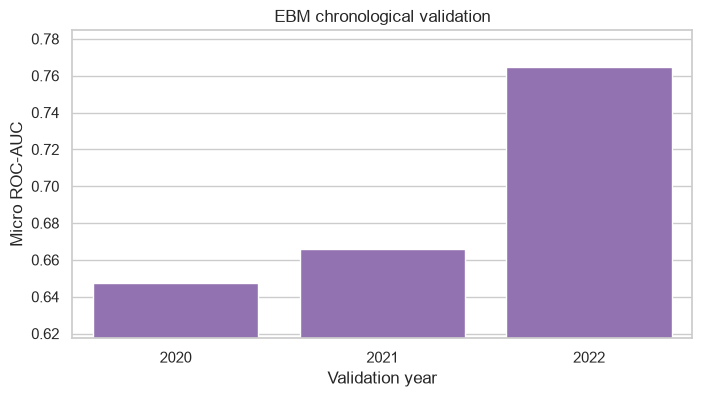

In [5]:
# FAST ANALYSIS CELL — no model fitting
unit_summary = (
    ebm_result["unit_scores"]
    .groupby("unit")["auc"]
    .agg(["mean", "min"])
    .sort_values("mean")
)
display(unit_summary.style.format("{:.4f}"))

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(
    data=ebm_fold_scores,
    x="validation_year",
    y="micro_auc",
    color="tab:purple",
    ax=ax,
)
ax.set(
    title="EBM chronological validation",
    xlabel="Validation year",
    ylabel="Micro ROC-AUC",
)
ax.set_ylim(
    max(0.5, ebm_fold_scores["micro_auc"].min() - 0.03),
    min(1.0, ebm_fold_scores["micro_auc"].max() + 0.02),
)
plt.show()


## 3. Full training, submission, and glass-box importance

In [6]:
# TRAINING CELL B — final runtime-controlled EBM models
train_rows_full = rows_for_cases(np.arange(data.n_train_cases))
selected = sampled_row_positions(
    len(train_rows_full),
    TRAIN_ROW_FRACTION,
    RANDOM_SEED,
)
train_rows = train_rows_full[selected]
test_rows = rows_for_cases(
    np.arange(data.n_train_cases, data.n_all_cases)
)
X_train_full = data.X_all.loc[train_rows, FEATURES]
X_test = data.X_all.loc[test_rows, FEATURES]
test_prediction = np.empty(
    (data.n_test_cases, len(data.units), HORIZON),
    dtype=np.float32,
)
final_models = {}

print(
    f"Final training uses {len(train_rows):,} of "
    f"{len(train_rows_full):,} case-hour rows"
)
for unit_index, unit in enumerate(data.units):
    y_train_full = data.target_cube[:, unit_index, :].reshape(-1)
    y_train = y_train_full[selected]
    model = make_ebm(RANDOM_SEED + unit_index)
    model.fit(X_train_full, y_train)
    prediction = model.predict_proba(X_test)[:, 1]
    test_prediction[:, unit_index, :] = prediction.reshape(
        data.n_test_cases, HORIZON
    )
    final_models[unit] = model
    print("Finished:", unit)

submission_path, submission = make_submission(
    data,
    test_prediction,
    "ebm_per_generator.csv",
)
print("Saved:", submission_path)
display(submission.iloc[:3, :8])


Final training uses 147,268 of 490,896 case-hour rows
Finished: Hogga_G1
Finished: Tokke_G1
Finished: Tokke_G2
Finished: Tokke_G3
Finished: Tokke_G4
Finished: Lio_G1
Finished: Byrte_G1
Finished: Vinje_G1
Finished: Vinje_G2
Finished: Vinje_G3
Finished: Haukeli_G1
Finished: Songa_G1
Finished: Kjela_G1
Finished: Vesle Kjela_G1
Saved: /Users/henrik/Documents/H26/Moderne Maksinlæring/sintef_project/submissions/ebm_per_generator.csv


,Run No,result_committed_Hogga_G1_t0,result_committed_Hogga_G1_t1,result_committed_Hogga_G1_t2,result_committed_Hogga_G1_t3,result_committed_Hogga_G1_t4,result_committed_Hogga_G1_t5,result_committed_Hogga_G1_t6
0,2923,0.780852,0.620593,0.549549,0.641460,0.610184,0.547571,0.120825
1,2924,0.329958,0.347078,0.339245,0.318034,0.395966,0.381636,0.595810
2,2925,0.445143,0.477031,0.475034,0.478329,0.701675,0.669736,0.767041


,term,importance
36,water_value_end_mean,1.239982
27,price_to_abs_water_value_ratio,0.886559
34,system_filling_ratio,0.876618
29,price_week_mean,0.671746
13,month_sin,0.545660
6,inflow_total_week_mean,0.491161
7,inflow_total_week_std,0.457979
32,price_week_std,0.455468
24,price_minus_water_value_mean & system_filling_...,0.394508
22,price_minus_water_value_mean,0.389081


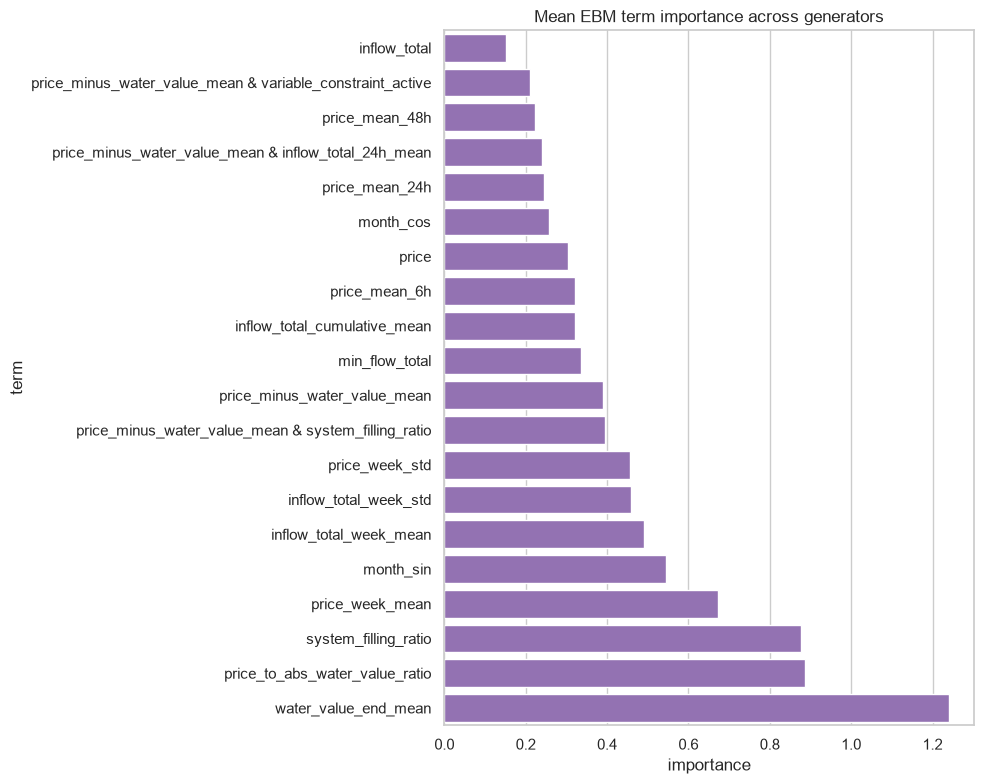

Saved: /Users/henrik/Documents/H26/Moderne Maksinlæring/sintef_project/artifacts/ebm_term_importance.csv


In [7]:
# INTERPRETATION CELL — uses already-fitted final models
importance_frames = []
for unit, model in final_models.items():
    importance_frames.append(pd.DataFrame({
        "unit": unit,
        "term": model.term_names_,
        "importance": model.term_importances(),
    }))

ebm_importance = pd.concat(importance_frames, ignore_index=True)
mean_importance = (
    ebm_importance.groupby("term", as_index=False)["importance"]
    .mean()
    .sort_values("importance", ascending=False)
)
importance_path = ROOT / "artifacts" / "ebm_term_importance.csv"
importance_path.parent.mkdir(parents=True, exist_ok=True)
mean_importance.to_csv(importance_path, index=False)

display(mean_importance.head(25))
fig, ax = plt.subplots(figsize=(10, 8))
plot_data = mean_importance.head(20).sort_values("importance")
sns.barplot(
    data=plot_data,
    x="importance",
    y="term",
    color="tab:purple",
    ax=ax,
)
ax.set(title="Mean EBM term importance across generators")
plt.tight_layout()
plt.show()
print("Saved:", importance_path)


### Kaggle description

`EBM per generator – runtime-controlled GAM – 30% rows and four physical interactions`

Promote it mainly if it is robust on the weakest fold or adds low-correlated OOF errors.
